# 1-12 기업집단 대시보드 — 그룹별 시가총액과 수익률 (신규)

**질문 예시:** "삼성·SK·현대차 그룹 시가총액이랑 올해 수익률 비교해줘", "삼성그룹 계열 상장사 중 뭐가 제일 많이 올랐어?"

CHECK 데이터에는 기업집단(그룹) 분류가 없습니다. DeepSearch는 상장사마다 **기업집단 ID**를 붙여 두고 그룹 정보를 따로 제공합니다.

| 단계 | DeepSearch |
|---|---|
| 상장사 → 그룹 | `GetStockSymbols()`의 `conglomerate_id` (전 종목 한 번) |
| 그룹 이름·대기업집단 여부 | `FindConglomerateByID([...])` (한 번), `top30`=1 이 대기업집단 |
| 그룹 계열사 전체(비상장 포함) | `GetConglomerateMembers(id)` |
| 시가총액·수익률 | 날짜별 전 종목 시세(`GetStockPrices`) 4번 |

[![Colab에서 열기](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/beaten-by-the-market/deepsearch/blob/main/scenarios/1_fundamentals/12_conglomerate_dashboard.ipynb)

## 0. 준비
Colab 왼쪽 🔑(Secrets)에 `DEEPSEARCH_API_KEY`를 등록하고 이 노트북의 액세스를 켠 뒤 아래 두 셀을 실행하세요. 두 번째 셀은 모든 시나리오에 공통인 헬퍼입니다(접어 두어도 됩니다).

In [1]:
# Colab에서만: 한글 차트 폰트 설치 (로컬에서는 건너뜀)
import sys
if "google.colab" in sys.modules:
    !pip -q install koreanize-matplotlib

In [2]:
# ── DeepSearch 헬퍼 (모든 시나리오 노트북 공통) ─────────────────────────────
# Colab: 왼쪽 🔑(Secrets)에 이름 DEEPSEARCH_API_KEY 로 키를 넣고 "노트북 액세스"를 켜세요.
#        키는 "아이디:비밀번호" 형식이든 base64 문자열이든 됩니다. 키 값은 출력하지 않습니다.
# 로컬: 환경변수 DEEPSEARCH_API_KEY / API_KEY 또는 상위 폴더의 .env 를 읽습니다.
import base64, json, os, sys, time
from datetime import date, datetime, timedelta

import pandas as pd
import requests

IN_COLAB = "google.colab" in sys.modules
API_URL = "https://api.deepsearch.com/v1/compute"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)


def _norm_key(k):
    k = k.strip().strip('"').strip("'")
    return base64.b64encode(k.encode()).decode() if ":" in k else k


def _find_key():
    if IN_COLAB:
        try:
            from google.colab import userdata
            k = userdata.get("DEEPSEARCH_API_KEY")
            if k:
                return _norm_key(k)
        except Exception:
            pass
    for name in ("DEEPSEARCH_API_KEY", "API_KEY"):
        if os.environ.get(name):
            return _norm_key(os.environ[name])
    d = os.path.abspath(os.getcwd())
    while True:
        p = os.path.join(d, ".env")
        if os.path.isfile(p):
            for line in open(p, encoding="utf-8-sig"):
                if "=" in line and not line.strip().startswith("#"):
                    k, v = line.split("=", 1)
                    if k.strip() in ("DEEPSEARCH_API_KEY", "API_KEY") and v.strip():
                        return _norm_key(v)
        if os.path.dirname(d) == d:
            break
        d = os.path.dirname(d)
    from getpass import getpass
    return _norm_key(getpass("DeepSearch API 키: "))


_KEY = _find_key()


class DSError(Exception):
    pass


def ds(query, timeout=180, retries=3):
    """compute 호출 → 응답 JSON. 서버가 돌려준 오류(data.exceptions)는 DSError."""
    last = None
    for i in range(retries):
        try:
            r = requests.post(API_URL, json={"input": query}, timeout=timeout,
                              headers={"Authorization": "Basic " + _KEY})
            body = r.json()
        except Exception as e:  # 네트워크·일시 오류만 재시도
            last = e
            time.sleep(3 * (i + 1))
            continue
        exc = (body.get("data") or {}).get("exceptions") or []
        if exc or r.status_code >= 400:
            msg = "; ".join(f"{x.get('class', '')}: {' '.join(map(str, x.get('args') or [x.get('message', '')]))}"
                            if isinstance(x, dict) else str(x) for x in exc)
            raise DSError(f"{r.status_code} {msg or body}"[:500])
        return body
    raise DSError(f"요청 실패: {last}")


def _pod(body):
    pods = (body.get("data") or {}).get("pods") or []
    return pods[1] if len(pods) >= 2 else {}


def ds_df(query, **kw):
    """DataFrame 결과(재무·시세·경제지표 등) → pandas DataFrame. 결과가 없으면 빈 DataFrame."""
    c = _pod(ds(query, **kw)).get("content") or {}
    data = c.get("data") if isinstance(c, dict) else None
    if not isinstance(data, dict) or not data:
        return pd.DataFrame()
    cols = [x for x in (c.get("columns") or data.keys()) if x in data]
    df = pd.DataFrame({x: data[x] for x in cols})
    for x in ("date", "created_at"):
        if x in df and df[x].dtype == object:
            df[x] = pd.to_datetime(df[x].astype(str).str[:19], errors="coerce")
    return df


def _polarity(x):
    """문서 긍부정: polarity.name, 없으면 customized_ml.kis 모델 값(최근 뉴스는 절반가량이 이쪽에만 있음)."""
    p = x.get("polarity")
    if isinstance(p, dict) and p.get("name"):
        return p["name"]
    k = (((x.get("customized_ml") or {}).get("kis") or {}).get("ip_multitask") or {}).get("polarity") or {}
    return k.get("name")


def doc_search(category, section, query, date_from, date_to, count=100, pages=1):
    """DocumentSearch → (총건수, 문서 DataFrame). category: news/research/company/patent. 기간은 1년 이내.
    종목 지정은 securities.symbol:005930 (접두어 없는 6자리)이 뉴스·리서치·공시 모두에서 가장 정확합니다.
    securities.symbol:KRX:005930 은 키워드 검색으로 바뀌어 건수가 줄고, securities.name: 은 리서치(공식명
    '에스케이하이닉스')·공시(DART명 '현대자동차')에서 놓칩니다(2026-11-25 확인). 여러 종목: securities.symbol:(005930 or 000660)"""
    rows, total = [], 0
    for page in range(1, pages + 1):
        q = (f'DocumentSearch(["{category}"],{json.dumps(section, ensure_ascii=False)},'
             f'{json.dumps(query, ensure_ascii=False)},count={count},page={page},'
             f'date_from={date_from},date_to={date_to})')
        c = _pod(ds(q)).get("content") or {}
        d = c.get("data") if isinstance(c.get("data"), dict) else c
        total = d.get("total_matches") or 0
        docs = d.get("docs") or []
        for x in docs:
            secs = x.get("securities") or []
            rows.append({
                "created_at": pd.to_datetime(str(x.get("created_at"))[:19], errors="coerce"),
                "publisher": x.get("publisher"),
                "title": " ".join(str(x.get("title") or "").split()),
                "stocks": ", ".join(s.get("name", "") for s in secs),
                "symbols": ", ".join(s.get("symbol", "") for s in secs),
                "polarity": _polarity(x),
                "url": x.get("content_url"),
            })
        if len(docs) < count:
            break
    cols = ["created_at", "publisher", "title", "stocks", "symbols", "polarity", "url"]
    return total, pd.DataFrame(rows, columns=cols)


def doc_trends(category, section, query, date_from, date_to, interval="1d"):
    """DocumentTrends → DataFrame(date, count)."""
    q = (f'DocumentTrends(["{category}"],{json.dumps(section, ensure_ascii=False)},'
         f'{json.dumps(query, ensure_ascii=False)},interval="{interval}",'
         f'date_from={date_from},date_to={date_to})')
    c = _pod(ds(q)).get("content") or {}
    d = c.get("data") if isinstance(c.get("data"), dict) else c
    trends = d.get("trends") or []
    b = trends[0].get("buckets", []) if trends else []
    df = pd.DataFrame([{"date": x.get("key_as_string") or x.get("key"), "count": x.get("count", 0)} for x in b])
    if not df.empty:
        df["date"] = pd.to_datetime(df["date"].astype(str).str[:19], errors="coerce")
    return df


def stock_prices(entities, date_from, date_to, columns=None):
    """종목 목록의 일별 시세. entities 예: ["KRX:005930", "KRX:000660"] 또는 "KRX:005930".
    가격은 수정주가, 거래량·거래대금·시가총액은 당일 실제 값. change_rate 는 비율(0.01 = 1%)."""
    ents = [entities] if isinstance(entities, str) else list(entities)
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    q = (f'GetStockPrices([{", ".join(ents)}], columns={json.dumps(cols)}, '
         f'date_from={date_from}, date_to={date_to})')
    return ds_df(q)


_UNIVERSE = None


def universe():
    """현재 상장 종목 기본정보(GetStockSymbols 전 종목): symbol, name, market, industry_name 등.
    company_type_l1: 1 일반법인, 2 공기업(한국전력·기업은행 등 8종목), 8 ETF·ETN 등."""
    global _UNIVERSE
    if _UNIVERSE is None:
        u = ds_df("GetStockSymbols()")
        _UNIVERSE = u.rename(columns={"entity_name": "name"})[
            ["symbol", "name", "market", "company_type_l1", "industry_id", "industry_name", "date_listed",
             "fiscal_year_end", "conglomerate_id"]]
    return _UNIVERSE.copy()


def all_stocks(day, common_only=True, columns=None):
    """day(또는 그 이전 마지막 거래일)의 전 종목 하루치 시세 + 종목 정보. 한 번 호출로 4,000여 종목.
    common_only=True 이면 일반법인·공기업 보통주만(ETF·ETN·우선주 제외)."""
    day = pd.Timestamp(day).date()
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    snap = ds_df(f'GetStockPrices(columns={json.dumps(cols)}, '
                 f'date_from={day - timedelta(days=7)}, date_to={day})')
    df = snap.merge(universe().drop(columns=["date"], errors="ignore"), on="symbol", how="left")
    if common_only:
        df = df[df["company_type_l1"].isin(["1", "2"]) & df["symbol"].str.endswith("0")]
    df = df[df["market"].isin(["KOSPI", "KOSDAQ", "KONEX"])]
    if "change_rate" in df:
        df["change_pct"] = df["change_rate"] * 100
    return df.reset_index(drop=True)


def index_prices(date_from, date_to):
    """지수 11종(코스피·코스닥 계열) 일별. change_rate 는 퍼센트(1.94 = 1.94%).
    지수의 value(거래대금)는 백만원, volume(거래량)은 천주 단위로 보입니다(코스닥 2026-11-23 value 4,673,819 ≈ 4.7조)."""
    # 지수를 지정하지 않으면 최근 약 1,300행(≈118거래일)만 오고 앞 기간이 조용히 잘린다 → 140일씩 나눠 받는다
    start, end = pd.Timestamp(date_from), pd.Timestamp(date_to)
    parts = []
    while start <= end:
        stop = min(start + pd.Timedelta(days=139), end)
        parts.append(ds_df(f"GetMarketIndexes(date_from={start.date()}, date_to={stop.date()})"))
        start = stop + pd.Timedelta(days=1)
    df = pd.concat([x for x in parts if not x.empty], ignore_index=True) if parts else pd.DataFrame()
    return df.drop_duplicates(["date", "symbol"]).sort_values(["date", "symbol"]).reset_index(drop=True) if not df.empty else df


def fred(series, date_from, date_to):
    """FRED 시리즈 → 날짜 × 시리즈 넓은 표. 예: fred(["DGS10", "DEXKOUS"], "2026-10-01", "2026-11-24")"""
    ids = ", ".join(json.dumps(s) for s in series)
    df = ds_df(f"QueryFredSeriesData([{ids}], date_from={date_from}, date_to={date_to})")
    if df.empty:
        return df
    val = [c for c in df.columns if c not in ("entity_id", "date")][0]
    df["series"] = df["entity_id"].str.replace("FRED:", "", regex=False)
    wide = df.pivot_table(index="date", columns="series", values=val).sort_index()
    return wide[[s for s in series if s in wide.columns]]  # 요청한 순서대로


def krw(v, digits=1):
    """원 → '138.0조' / '5,027억'."""
    if v is None or pd.isna(v):
        return "-"
    a = abs(v)
    if a >= 1e12:
        return f"{v / 1e12:.{digits}f}조"
    if a >= 1e8:
        return f"{v / 1e8:,.0f}억"
    if a >= 1e4:
        return f"{v / 1e4:,.0f}만"
    return f"{v:,.0f}"


PRICE_NOTICE = ("※ 주가는 수정주가입니다(분할·무상증자·유상증자 소급 반영, 배당 미반영). "
                "거래량·거래대금·시가총액은 당일 실제 값이며 KRX 기준입니다(NXT 미포함).")

# 한글 차트 폰트
import matplotlib.pyplot as plt
try:
    import koreanize_matplotlib  # noqa: F401  (Colab: 위 셀에서 설치)
except ImportError:
    if sys.platform.startswith("win"):
        plt.rcParams["font.family"] = "Malgun Gothic"
    elif sys.platform == "darwin":
        plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

print("DeepSearch 준비 완료", "(Colab)" if IN_COLAB else "(로컬)")

DeepSearch 준비 완료 (로컬)


In [3]:
ASOF = "2026-11-24"
HORIZONS = {"1개월": pd.DateOffset(months=1), "3개월": pd.DateOffset(months=3), "연초 이후": None}
DETAIL_GROUP = "삼성"
print(PRICE_NOTICE)

※ 주가는 수정주가입니다(분할·무상증자·유상증자 소급 반영, 배당 미반영). 거래량·거래대금·시가총액은 당일 실제 값이며 KRX 기준입니다(NXT 미포함).


## 1. 상장사와 그룹 연결

In [4]:
sym = ds_df("GetStockSymbols()")
sym = sym[(sym["company_type_l1"] == "1") & sym["symbol"].str.endswith("0") & sym["market"].isin(["KOSPI", "KOSDAQ"])]
ids = sorted(sym["conglomerate_id"].dropna().unique())
grp = ds_df("FindConglomerateByID([" + ", ".join(f'"{i}"' for i in ids) + "])")
grp = grp[["conglomerate_id", "name_ko", "owner", "top30", "member_count", "main_company_name"]].rename(
    columns={"name_ko": "그룹", "owner": "동일인", "member_count": "계열사 수"})
big = grp[grp["top30"].astype(str) == "1"]
print(f"그룹 ID가 있는 상장사 {sym['conglomerate_id'].notna().sum()}곳 / 그룹 {len(grp)}개 중 대기업집단(top30=1) {len(big)}개")

그룹 ID가 있는 상장사 2076곳 / 그룹 1328개 중 대기업집단(top30=1) 44개


## 2. 날짜별 전 종목 시세
기준일, 1개월 전, 3개월 전, 작년 마지막 거래일 — 4번 호출합니다. 수익률은 **시작 시점 시가총액 가중**(그 사이 상장한 종목은 제외)입니다.

In [5]:
asof = pd.Timestamp(ASOF)
dates = {"기준": asof}
for k, off in HORIZONS.items():
    dates[k] = asof - off if off is not None else pd.Timestamp(f"{asof.year - 1}-12-31")
snaps = {}
for k, d in dates.items():
    a = all_stocks(d.date())
    snaps[k] = a[["symbol", "name", "close", "market_cap"]].set_index("symbol")
    print(f"{k:6} → 거래일 {a['date'].max().date()} ({len(a)}종목)")
now = snaps["기준"].join(sym.set_index("symbol")[["conglomerate_id"]], how="inner").reset_index()
now = now.merge(grp, on="conglomerate_id", how="left")

def group_return(members, start_key):
    s0 = snaps[start_key].reindex(members["symbol"]).dropna()
    if s0.empty:
        return float("nan")
    p1 = snaps["기준"].reindex(s0.index)["close"]
    w = s0["market_cap"]
    return (w * (p1 / s0["close"] - 1)).sum() / w.sum()

기준     → 거래일 2026-11-24 (2770종목)


1개월    → 거래일 2026-10-23 (2752종목)


3개월    → 거래일 2026-08-24 (2735종목)


연초 이후  → 거래일 2025-12-30 (2691종목)


## 3. 대기업집단 순위

In [6]:
total_cap = snaps["기준"]["market_cap"].sum()
rows = []
for cid, g in now[now["conglomerate_id"].isin(big["conglomerate_id"])].groupby("conglomerate_id"):
    r = {"그룹": g["그룹"].iloc[0], "동일인": g["동일인"].iloc[0], "상장사": len(g), "계열사 수": g["계열사 수"].iloc[0],
         "시가총액": g["market_cap"].sum(), "시장 비중": g["market_cap"].sum() / total_cap,
         "대표 상장사": g.sort_values("market_cap", ascending=False)["name"].head(3).str.cat(sep=", ")}
    for k in HORIZONS:
        r[k] = group_return(g, k)
    rows.append(r)
board = pd.DataFrame(rows).sort_values("시가총액", ascending=False).reset_index(drop=True)
show = board.copy()
show["시가총액"] = show["시가총액"].map(krw)
show["시장 비중"] = (show["시장 비중"] * 100).map("{:.1f}%".format)
for k in HORIZONS:
    show[k] = (show[k] * 100).map("{:+.1f}%".format)
print(f"코스피+코스닥 일반 보통주 시가총액 {krw(total_cap)} 기준")
show.head(20)

코스피+코스닥 일반 보통주 시가총액 4348.4조 기준


,그룹,동일인,상장사,계열사 수,시가총액,시장 비중,대표 상장사,1개월,3개월,연초 이후
0,삼성,이재용,18,63.0,1448.7조,33.3%,"삼성전자, 삼성전기, 삼성바이오로직스",-11.9%,-25.1%,+46.2%
1,에스케이,최태원,18,198.0,1001.9조,23.0%,"SK하이닉스, SK스퀘어, SK",-9.2%,-30.2%,+70.8%
2,현대자동차,정의선,12,74.0,171.5조,3.9%,"현대차, 기아, 현대모비스",-4.2%,-28.8%,-14.2%
3,엘지,구광모,12,63.0,153.4조,3.5%,"LG에너지솔루션, LG전자, LG화학",-13.2%,-19.7%,-7.8%
4,HD현대,정몽준,8,32.0,79.7조,1.8%,"HD현대중공업, HD한국조선해양, HD현대일렉트릭",-14.2%,-40.5%,-44.4%
5,한화,김승연,12,119.0,72.2조,1.7%,"한화에어로스페이스, 한화오션, 한화시스템",-22.3%,-40.5%,-37.3%
6,셀트리온,서정진,2,9.0,50.3조,1.2%,"셀트리온, 셀트리온제약",+7.5%,+7.2%,+12.8%
7,포스코,포스코홀딩스(주),6,49.0,47.5조,1.1%,"POSCO홀딩스, 포스코퓨처엠, 포스코인터내셔널",-2.5%,-12.7%,-13.6%
8,두산,박정원,7,24.0,47.4조,1.1%,"두산에너빌리티, 두산, 두산밥캣",-26.3%,-38.2%,-34.7%
9,엘에스,구자은,10,72.0,34.7조,0.8%,"LS ELECTRIC, 가온전선, LS",-19.0%,-27.5%,-36.2%


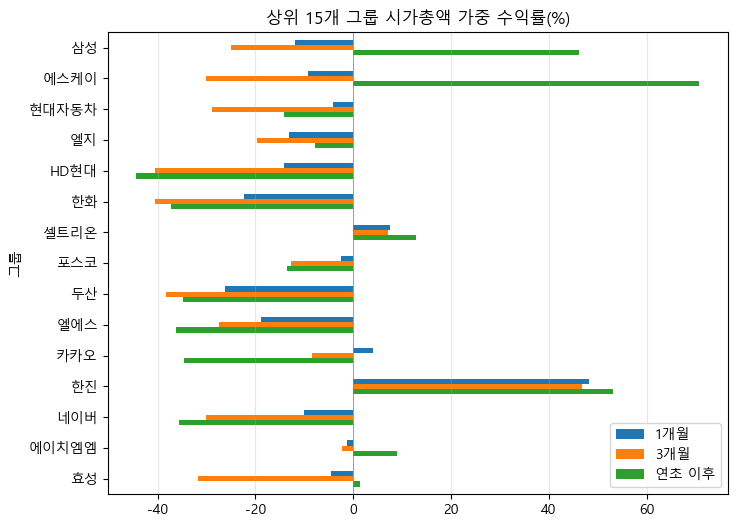

In [7]:
top = board.head(15).set_index("그룹")[list(HORIZONS)] * 100
ax = top.plot.barh(figsize=(8, 6), title="상위 15개 그룹 시가총액 가중 수익률(%)")
ax.invert_yaxis(); ax.axvline(0, color="gray", lw=.5); ax.grid(alpha=.3, axis="x")

## 4. 한 그룹 자세히 보기
그룹 안에서 시가총액 비중과 종목별 수익률을 봅니다. 비상장 계열사까지 포함한 전체 명단은 `GetConglomerateMembers`로 받습니다.

In [8]:
cid = board.merge(grp, on="그룹").query("그룹 == @DETAIL_GROUP")["conglomerate_id"].iloc[0]
g = now[now["conglomerate_id"] == cid].copy()
g["그룹 내 비중"] = g["market_cap"] / g["market_cap"].sum()
for k in HORIZONS:
    s0 = snaps[k]["close"]
    g[k] = g["symbol"].map(lambda x: snaps["기준"]["close"].get(x) / s0.get(x) - 1 if x in s0.index else float("nan"))
out = g.sort_values("market_cap", ascending=False)[["name", "close", "market_cap", "그룹 내 비중"] + list(HORIZONS)].copy()
out["market_cap"] = out["market_cap"].map(krw)
out["그룹 내 비중"] = (out["그룹 내 비중"] * 100).map("{:.1f}%".format)
for k in HORIZONS:
    out[k] = (out[k] * 100).map(lambda v: "-" if pd.isna(v) else f"{v:+.1f}%")
members = ds_df(f'GetConglomerateMembers("{cid}")')
print(f"{DETAIL_GROUP} 그룹: 계열사 {len(members)}곳(사업연도 {members['fiscal_year'].max()}) 중 상장 {len(g)}곳")
out.rename(columns={"name": "종목", "close": "종가", "market_cap": "시가총액"})

삼성 그룹: 계열사 63곳(사업연도 2025) 중 상장 18곳


,종목,종가,시가총액,그룹 내 비중,1개월,3개월,연초 이후
1642,삼성전자,189400,1107.3조,76.4%,-12.1%,-26.3%,+58.0%
1540,삼성전기,858000,64.1조,4.4%,-23.5%,-34.9%,+236.5%
346,삼성바이오로직스,1290000,59.7조,4.1%,-12.0%,-18.0%,-23.9%
2267,삼성생명,247000,49.4조,3.4%,+0.8%,-13.5%,+56.7%
2294,삼성물산,265500,43.1조,3.0%,-7.8%,-27.2%,+10.9%
1517,삼성SDI,450000,36.3조,2.5%,-8.3%,-12.6%,+67.0%
1429,삼성화재,511000,22.8조,1.6%,-15.1%,-19.7%,+2.8%
1238,삼성에스디에스,184200,14.3조,1.0%,-13.7%,-19.2%,+7.4%
1067,삼성중공업,14970,13.2조,0.9%,-11.1%,-25.5%,-37.9%
2292,삼성E&A,59700,11.7조,0.8%,-0.2%,+33.3%,+148.2%


## 결과 읽는 법과 한계
- 그룹 수익률은 계열 상장사를 **시작 시점 시가총액으로 가중**한 값이라 대형 계열사(삼성전자, SK하이닉스 등)가 좌우합니다.
- 그룹 소속은 **현재 기준**입니다. 기간 중 계열 편입·제외된 회사도 지금 소속으로 계산됩니다.
- 우선주와 ETF는 뺐습니다. 리츠는 일반법인으로 분류돼 포함될 수 있습니다(예: 삼성FN리츠). 지주회사와 자회사가 함께 상장된 그룹은 시가총액이 이중으로 잡히는 면이 있습니다.
- 대기업집단 표시(`top30`=1)는 DeepSearch 분류이고 공정위 지정 목록과 정확히 같지 않을 수 있습니다.